# Decile Testing

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Global Variables and Data

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
src_path  = os.path.join(repo_path, "src")
data_path = os.path.join(repo_path, "data")

In [3]:
sys.path.append(src_path)
from QuantileFitter import QuantileFitter

In [4]:
trend_path = os.path.join(data_path, "GenericTrendSignal.parquet")
df_data    = (pd
    .read_parquet(path = trend_path, engine = "pyarrow")
    .assign(signal_name = lambda x: x.Ticker + "_" + x.window.astype(str)))

In [5]:
print(src_path)

A:\GitHub\SignalTrader\src


# Decile Models

In [6]:
df_data.head(3)

,Ticker,Date,lag_signal,signal,window,rtn,signal_name
0,AGG,2003-10-01,NaN,-0.121794,8,-0.000486,AGG_8
1,AGG,2003-10-02,-0.121794,-0.177490,8,-0.001559,AGG_8
2,AGG,2003-10-03,-0.177490,-0.403561,8,-0.007219,AGG_8


In [7]:
quintile_fitter = (QuantileFitter(
    rtn_col    = "rtn", 
    group_col  = "signal_name",
    date_col   = "Date"))

In [8]:
df_full_sample = quintile_fitter.fit_quantile_full_sample(df_data, "signal")

<Axes: xlabel='Date'>

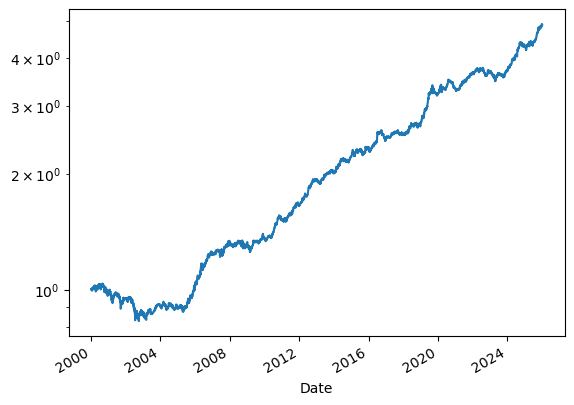

In [9]:
(df_full_sample
    ["data"]
    .assign(signal_rtn = lambda x: np.where(x.signal_rtn == 0, np.nan, x.signal_rtn))
    .dropna()
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .mean(axis = 1).to_frame(name = "tmp")
    .apply(lambda x: np.cumprod(1 + x))
    .plot(logy = True, legend = False))

In [25]:
full_sample     = quintile_fitter.fit_quantile_full_sample(df_data, "signal")
full_sample_rtn = quintile_fitter.get_quantile_data(full_sample)

In [27]:
train_test     = quintile_fitter.fit_quantile_train_test_ratio(df_data, "signal")
train_test_rtn = quintile_fitter.get_quantile_data(train_test)

In [29]:
expanding_test = quintile_fitter.fit_quantile_expanding(df_data, "signal")
expanding_rtn  = quintile_fitter.get_quantile_data(expanding_test)

In [36]:
df_is = (full_sample_rtn
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .mean(axis = 1)
    .to_frame(name = "in_sample"))

In [42]:
df_train_test = (train_test_rtn
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .mean(axis = 1)
    .to_frame(name = "train_test"))

In [47]:
(expanding_rtn
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(la))

signal_name,AGG_128,AGG_16,AGG_32,AGG_64,AGG_8,BND_128,BND_16,BND_32,BND_64,BND_8,...,VEA_128,VEA_16,VEA_32,VEA_64,VEA_8,VWO_128,VWO_16,VWO_32,VWO_64,VWO_8
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-0.002239,-0.002239,-0.002239,-0.0,-0.0,-0.0,-0.0,-0.0
2025-12-26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-0.002074,-0.002074,-0.002074,0.0,0.0,0.0,0.0,0.0
2025-12-29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.0,-0.0,0.001433,0.001433,0.001433,-0.0,-0.0,-0.0,-0.0,-0.0
